# 07 · k-Nearest Neighbours (handbook 3.5.5)
kNN relies on distances. On thousands of mostly one-hot columns those distances are noisy and slow,
so the features are first compressed with **TruncatedSVD** (50 components, fitted on train only).

In [1]:
import sys
from pathlib import Path

# find the project root (the folder that contains src/dsc_utils.py) and import the shared helpers
root = Path.cwd()
while not (root / "src" / "dsc_utils.py").exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dsc_utils import *

d = load_prepared()
x_train, x_val, x_test = d["x_train"], d["x_val"], d["x_test"]
y_train, y_val, y_test = d["y_train"], d["y_val"], d["y_test"]
feature_names = d["feature_names"]
print("train", x_train.shape, "| val", x_val.shape, "| test", x_test.shape)
from sklearn.decomposition import TruncatedSVD
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline

train (114844, 1711) | val (28712, 1711) | test (35890, 1711)


In [2]:
svd = TruncatedSVD(n_components=50, random_state=0).fit(x_train)
print("Variance kept:", svd.explained_variance_ratio_.sum().round(3))
z_train, z_val = svd.transform(x_train), svd.transform(x_val)
zv, yv = stratified_sample(z_val, y_val, 10000)       # smaller validation sample: prediction is the slow part

Variance kept: 0.783


## 1-NN vs. 600-NN, uniform vs. inverse-distance weights (handbook exercises 1-4)

In [3]:
for k, w in [(1, "uniform"), (600, "uniform"), (600, "distance")]:
    m = KNeighborsClassifier(n_neighbors=k, weights=w, n_jobs=-1).fit(z_train, y_train)
    p = m.predict_proba(zv)
    print(f"k={k:<4} {w:<9} macro-F1 = {macro_f1(yv, m.classes_[p.argmax(1)]):.4f} | "
          f"distinct score rows = {len(np.unique(p.round(3), axis=0))}")

k=1    uniform   macro-F1 = 0.4384 | distinct score rows = 8
k=600  uniform   macro-F1 = 0.4079 | distinct score rows = 9987
k=600  distance  macro-F1 = 0.4337 | distinct score rows = 9873


## Grid search over k with inverse-distance weights (handbook exercise 5)

1 0.4384
5 0.4745
15 0.4929
31 0.4936
51 0.498
101 0.4876
201 0.4662
401 0.4459
Optimal number of neighbours: 51


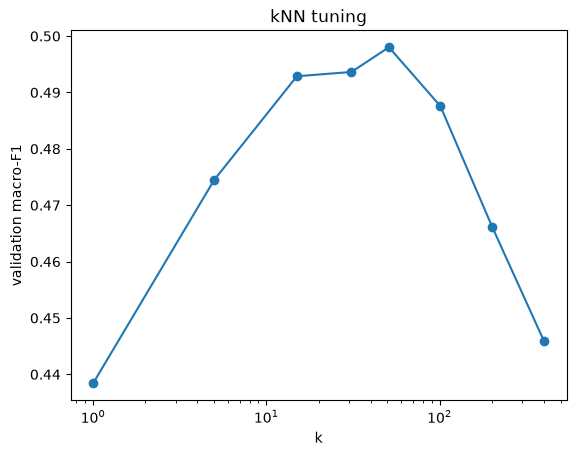

In [4]:
K = [1, 5, 15, 31, 51, 101, 201, 401]
f1_val = []
for k in K:
    m = KNeighborsClassifier(n_neighbors=k, weights="distance", n_jobs=-1).fit(z_train, y_train)
    f1_val.append(macro_f1(yv, m.predict(zv)))
    print(k, round(f1_val[-1], 4))
k_opt = K[int(np.argmax(f1_val))]
print("Optimal number of neighbours:", k_opt)
plt.plot(K, f1_val, marker="o"); plt.xscale("log")
plt.xlabel("k"); plt.ylabel("validation macro-F1"); plt.title("kNN tuning"); plt.show()

## Final kNN (SVD + kNN in one pipeline): evaluate on test and save

{'model': 'kNN (SVD-50)', 'accuracy': 0.5162, 'macro_F1': 0.4884, 'ordinal_MAE': 0.7516, 'within_one': 0.8154, 'EFG_recall': 0.7473, 'AUC_ovr': 0.8782}


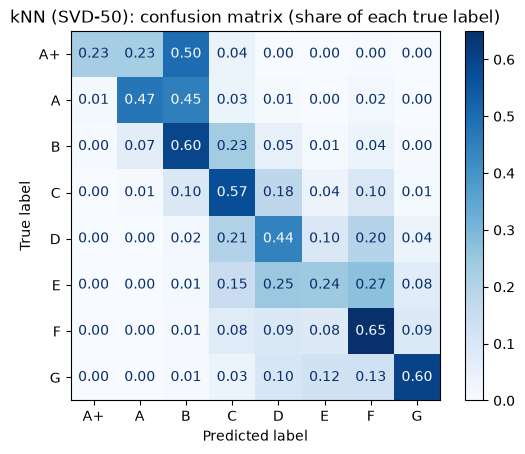

In [5]:
KNN = make_pipeline(TruncatedSVD(n_components=50, random_state=0),
                    KNeighborsClassifier(n_neighbors=k_opt, weights="distance", n_jobs=-1))
KNN.fit(x_train, y_train)
evaluate("kNN (SVD-50)", KNN, x_test, y_test)
save_model(KNN, "KNN")